# Fase 2 — Projeto 1 · Otimização de Hiperparâmetros por Algoritmo Genético

**Aluno:** Icaro Minervini Americo — RM376755 · **Turma:** 10IADT
**Notebook 01 de 03** — o algoritmo genético aplicado aos modelos de diagnóstico de SOP (PCOS)

---

## Sumário

1. [O que este notebook faz, e por que](#etapa1)
2. [O ponto de partida: reproduzir a Fase 1](#etapa2)
3. [A codificação dos indivíduos](#etapa3)
   - [3.1 Por que codificação híbrida](#etapa3_1)
   - [3.2 O espaço de busca, gene por gene](#etapa3_2)
   - [3.3 Validade por construção](#etapa3_3)
4. [A função fitness](#etapa4)
   - [4.1 Por que não acurácia](#etapa4_1)
   - [4.2 A regra anti-vazamento](#etapa4_2)
5. [Hotstart: começar de onde a Fase 1 parou](#etapa5)
6. [Os operadores genéticos](#etapa6)
7. [Rodando o AG](#etapa7)
8. [O que foi feito e o que ficou de fora](#etapa8)


<a id="etapa1"></a>
## 1. O que este notebook faz, e por que

**O que.** A Fase 1 treinou cinco classificadores para prever Síndrome dos Ovários Policísticos
(SOP) e entregou os resultados com uma configuração de hiperparâmetros escolhida manualmente.
Este notebook usa um **algoritmo genético** para buscar automaticamente configurações melhores.

**Por que isso, e não uma busca em grade.** O próprio notebook de modelagem da Fase 1 encerra
listando *"ajuste de hiperparâmetros com GridSearchCV / validação cruzada"* como próximo passo
— ou seja, a Fase 2 é literalmente o passo que a Fase 1 anotou e não executou. O enunciado
pede especificamente algoritmo genético, e há uma razão conceitual para preferi-lo aqui: busca
em grade avalia um produto cartesiano fixo, enquanto o AG **concentra orçamento nas regiões
promissoras** ao longo das gerações.

**Como isso afeta os modelos.** O AG não muda os dados nem os algoritmos — muda apenas os
"botões" de cada modelo (profundidade da árvore, número de estimadores, `C` do SVM...). O
ganho possível, portanto, é limitado pelo que esses botões conseguem extrair dos mesmos 541
registros.

**Como cheguei a essa delimitação.** O plano de implementação (§2) registra a conta: um AG
sobre a CNN de raio-X da Fase 1 custaria ~27 horas, e com fitness de baixa fidelidade mediria
a coisa errada. Com o PCOS, 450 avaliações levam ~30 segundos. A decisão foi restringir o
escopo ao PCOS e usar o orçamento liberado para fazer **mais experimentos sobre o próprio AG**
— incluindo uma ablação do operador de seleção e uma comparação contra busca aleatória.


> ⚠️ **Ponto de atenção — ativar o ambiente antes de abrir o Jupyter.**
> O kernel resolve `python` pelo `PATH`. Se o Jupyter foi iniciado fora do venv, os `import`
> deste notebook falham mesmo com as dependências instaladas:
> ```bash
> cd ~/Documents/pos-tech-fiap-ia-dev-fase-2
> source .venv/bin/activate
> jupyter lab
> ```


In [1]:
import sys
from pathlib import Path

# permite importar `src.*` com o notebook rodando de dentro de notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

print("raiz do projeto:", RAIZ)


raiz do projeto: /Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2


<a id="etapa2"></a>
## 2. O ponto de partida: reproduzir a Fase 1

**O que.** Antes de otimizar qualquer coisa, reproduzo os números da Fase 1 e os congelo como
baseline.

**Por que isso vem primeiro.** Sem baseline verificado, todo ganho reportado depois é ficção:
não há como distinguir "o AG melhorou o modelo" de "o AG rodou num pipeline diferente do da
Fase 1". O script `src/modelagem/treinamento.py` é **cópia byte a byte** do original — não foi
alterado em nenhum ponto, de propósito, para que a comparação seja sobre a mesma base, o mesmo
split e a mesma semente.

**Como cheguei a esses números.** Rodando `python -m src.run_ml`, que executa o script copiado
e grava `arquivos_saida/arquivos_analiticos/metricas_modelos_baseline/metricas_modelos.json`. Os cinco modelos bateram com os valores documentados
na Fase 1 até a quarta casa decimal.


In [2]:
from src.experimentos.analise import BASELINE_FASE1, NOMES_AMIGAVEIS, score_composto

baseline = pd.DataFrame(BASELINE_FASE1).T
baseline.index = [NOMES_AMIGAVEIS[i] for i in baseline.index]
baseline["score_composto"] = [
    score_composto(r["f1_score"], r["recall"], r["auc_roc"]) for _, r in baseline.iterrows()
]
baseline.sort_values("score_composto", ascending=False)


,acuracia,precisao,recall,f1_score,auc_roc,score_composto
Random Forest,0.9174,0.9355,0.8056,0.8657,0.9365,0.8618
SVM (RBF),0.8807,0.8108,0.8333,0.8219,0.9315,0.8472
Regressão Logística,0.8532,0.7381,0.8611,0.7949,0.9277,0.8413
Árvore de Decisão,0.8624,0.8000,0.7778,0.7887,0.8809,0.8039
KNN,0.8624,0.8889,0.6667,0.7619,0.9007,0.7611


**O que a tabela mostra, e o detalhe que orienta toda a Fase 2:**

O Random Forest é o melhor modelo da Fase 1 em quase tudo — mas o **recall é sua métrica mais
fraca (0,8056)**, apesar da precisão altíssima (0,9355). Traduzindo: o modelo escolhido pela
Fase 1 deixa passar cerca de **19% das pacientes que têm a condição**.

Em diagnóstico médico, esse é justamente o erro que custa mais caro. Um falso positivo gera um
exame a mais; um falso negativo significa não tratar. É essa assimetria que define a função
fitness da §4 — e é a razão de o AG não otimizar acurácia.


<a id="etapa3"></a>
## 3. A codificação dos indivíduos

<a id="etapa3_1"></a>
### 3.1 Por que codificação híbrida

**O que.** Cada indivíduo do AG representa uma configuração completa: qual família de modelo
usar **e** quais hiperparâmetros aplicar nela.

**Por que híbrida e não binária.** Das quatro codificações usuais (binária, real, combinatória,
híbrida), a híbrida é a que deixa cada trecho do cromossomo representar um aspecto da solução
com restrições próprias. Hiperparâmetros são heterogêneos por
natureza — `n_estimators` é inteiro, `C` é real em escala logarítmica, `criterion` é
categórico, `bootstrap` é booleano. Forçar tudo em binário exigiria uma camada de decodificação
artificial e jogaria fora a estrutura do problema.

**Como isso afeta a busca.** Com um **gene 0 que escolhe a família**, o AG faz *seleção de
modelo e ajuste de hiperparâmetros ao mesmo tempo*. A pressão seletiva decide qual família
merece orçamento, em vez de eu decidir a priori. Isso gera uma pergunta que a Fase 1 não podia
responder: *o Random Forest continua ganhando quando todas as cinco famílias são bem
ajustadas?*

**O detalhe de implementação que importa — genes latentes.** Todo indivíduo carrega os genes de
**todas** as famílias simultaneamente, mesmo as inativas. Isso mantém o cromossomo de tamanho
fixo (crossover e mutação ficam triviais e sempre válidos) e cria um **reservatório de
diversidade**: se o gene de família mutar de SVM para Random Forest, os hiperparâmetros de RF
que o indivíduo carregava "adormecidos" voltam a ser expressos, em vez de serem sorteados do
zero. É o paralelo direto de material genético recessivo.


In [3]:
from src.ag.cromossomo import FAMILIAS, SCHEMA, gerar_individuo_aleatorio, decodificar

rng = np.random.default_rng(42)
exemplo = gerar_individuo_aleatorio(rng)

print("família ativa (gene 0):", exemplo["familia"])
print()
print("genes EXPRESSOS (os que afetam o modelo treinado):")
for nome, valor in exemplo[exemplo["familia"]].items():
    print(f"   {nome:22} = {valor}")
print()
print("genes LATENTES (carregados, não expressos — o reservatório recessivo):")
for familia in FAMILIAS:
    if familia != exemplo["familia"]:
        print(f"   {familia:22} = {len(exemplo[familia])} genes adormecidos")


família ativa (gene 0): random_forest

genes EXPRESSOS (os que afetam o modelo treinado):
   n_estimators           = 244
   max_depth              = 10
   min_samples_split      = 18
   min_samples_leaf       = 1
   max_features           = 0.5
   criterion              = gini
   class_weight           = None

genes LATENTES (carregados, não expressos — o reservatório recessivo):
   svm_rbf                = 3 genes adormecidos
   logistic_regression    = 4 genes adormecidos
   decision_tree          = 6 genes adormecidos
   knn                    = 4 genes adormecidos


<a id="etapa3_2"></a>
### 3.2 O espaço de busca, gene por gene

**O que.** O `SCHEMA` declara o tipo e os limites de cada gene. O tipo determina como o gene é
amostrado, cruzado e mutado — sem `if` espalhado pelo código.


In [4]:
linhas = []
for familia, genes in SCHEMA.items():
    for nome, spec in genes.items():
        faixa = (
            f"{spec['low']} … {spec['high']}" if "low" in spec
            else ", ".join(str(c) for c in spec["choices"])
        )
        linhas.append({"família": familia, "gene": nome, "tipo": spec["tipo"], "faixa/valores": faixa})

espaco = pd.DataFrame(linhas)
print(f"{len(espaco)} genes no total, distribuídos em {len(SCHEMA)} famílias\n")
espaco


24 genes no total, distribuídos em 5 famílias



,família,gene,tipo,faixa/valores
0,random_forest,n_estimators,int,50 … 300
1,random_forest,max_depth,int_or_none,2 … 20
2,random_forest,min_samples_split,int,2 … 20
3,random_forest,min_samples_leaf,int,1 … 10
4,random_forest,max_features,categorical,"sqrt, log2, 0.3, 0.5, 0.8"
5,random_forest,criterion,categorical,"gini, entropy"
6,random_forest,class_weight,categorical,"None, balanced"
7,svm_rbf,C,real_log,0.01 … 1000.0
8,svm_rbf,gamma,real_log,0.0001 … 10.0
9,svm_rbf,class_weight,categorical,"None, balanced"


**A decisão mais consequente desta tabela: `C` e `gamma` em escala logarítmica.**

**Por que.** A sensibilidade do SVM a esses parâmetros é **multiplicativa, não aditiva** — a
diferença entre `C=0,01` e `C=0,1` é tão relevante quanto entre `C=10` e `C=100`. Se o gene
guardasse o valor linear, uma mutação gaussiana sobre a faixa `[0,01; 1000]` quase nunca
sortearia valores abaixo de 1: metade do espaço útil ficaria inacessível.

**Como foi resolvido.** O gene guarda `log10(valor)` internamente e é exponenciado na
decodificação. Mutação e crossover acontecem em espaço logarítmico — o que faz o crossover
aritmético corresponder à **média geométrica** no espaço real, que é a operação correta nessa
escala.

> ⚠️ **Armadilha que custou um bug real.** Como o gene guarda `log10`, qualquer valor escrito
> em unidades do mundo real precisa ser **codificado** antes de entrar no cromossomo. Na
> primeira versão, a tabela de hotstart guardava `C=1.0` cru; a decodificação então calculava
> `10¹ = 10`, e `gamma=0.1` virava `10^0,1 = 1,26`. O SVM resultante superajustava e **previa
> tudo como negativo (F1 = 0,000)** — e passava desapercebido porque os testes só verificavam
> que o fitness estava entre 0 e 1. A correção foi criar `codificar_genes()`, a inversa
> explícita da decodificação, com um teste que fecha o ciclo nas cinco famílias.


<a id="etapa3_3"></a>
### 3.3 Validade por construção

**O que.** Nenhuma combinação de genes pode produzir um indivíduo que o scikit-learn rejeite.

**Por que isso é decisão de arquitetura, não detalhe.** **Validade da solução gerada** é um
dos dois critérios que todo operador precisa respeitar — o outro é custo. Num AG de
hiperparâmetros, um indivíduo inválido quebraria a execução na geração 7, depois de 20 minutos
rodando.

**Como foi garantido** — três mecanismos, todos *por construção* e não por reparo posterior:

| Restrição | Como é garantida |
|---|---|
| Genes dentro das faixas | `clamp_individuo()` após cada crossover e mutação |
| `penalty`/`solver` compatíveis | Herdados como **par atômico**, nunca recombinados entre si |
| `n_neighbors` sempre ímpar | Tipo de gene `int_odd` (evita empate em classificação binária) |
| `l1_ratio` só com `elasticnet` | Decodificação condicional — o gene existe mas não é expresso |

**Consequência prática:** não há `try/except` em volta do treino. Se houvesse, ele mascararia
indivíduos inválidos como "fitness zero" e o AG aprenderia a evitar regiões válidas do espaço
por motivo errado.


In [5]:
from src.ag.cromossomo import validar_individuo
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

CONSTRUTORES = {
    "random_forest": RandomForestClassifier, "svm_rbf": SVC,
    "logistic_regression": LogisticRegression, "decision_tree": DecisionTreeClassifier,
    "knn": KNeighborsClassifier,
}

# sorteia 300 indivíduos e INSTANCIA o estimador real de cada um
rng = np.random.default_rng(0)
falhas = []
for _ in range(300):
    ind = gerar_individuo_aleatorio(rng)
    assert validar_individuo(ind)
    familia, kwargs = decodificar(ind)
    try:
        kw = dict(kwargs)
        if familia != "knn":
            kw["random_state"] = 42
        CONSTRUTORES[familia](**kw)
    except Exception as erro:
        falhas.append((familia, kwargs, erro))

print(f"300 indivíduos aleatórios instanciados no scikit-learn → {len(falhas)} rejeições")


300 indivíduos aleatórios instanciados no scikit-learn → 0 rejeições


<a id="etapa4"></a>
## 4. A função fitness

<a id="etapa4_1"></a>
### 4.1 Por que não acurácia

**O que.** O fitness é um score composto:

$$\text{fitness} = 0{,}5 \cdot F_1 + 0{,}3 \cdot \text{recall} + 0{,}2 \cdot \text{AUC}$$

calculado como média sobre 5 dobras de validação cruzada estratificada.

**Por que não acurácia.** A função de fitness é específica do problema e tem de refletir os
objetivos e os critérios de desempenho desejados. O objetivo aqui é **diagnóstico
médico**, onde falso negativo e falso positivo não custam o mesmo. Acurácia trata os dois como
equivalentes — logo é a métrica errada para este problema.

**Como cheguei a esses pesos.** Da evidência da própria Fase 1 (tabela da §2): o Random Forest
vencedor tinha recall 0,8056 como métrica mais fraca. Então:

- **F1 com peso 0,5** — objetivo balanceado principal, já combina precisão e recall;
- **recall com peso extra 0,3** — empurra deliberadamente na direção da fraqueza conhecida;
- **AUC com peso 0,2** — premia separabilidade independente de limiar, o que **estabiliza** o
  fitness quando dois indivíduos empatam em F1.

**Como isso afeta o resultado — e a predição que fica registrada.** Se o fitness pesa recall, o
alelo `class_weight='balanced'` *deveria* se fixar na população ao longo das gerações. Isso é
uma **predição verificável sobre o meu próprio AG**, e vou rastreá-la no Notebook 02. Se ela se
confirmar, é evidência de que fitness e operadores funcionam como projetado.


<a id="etapa4_2"></a>
### 4.2 A regra anti-vazamento

> 🔴 **A regra mais importante de todo o projeto: o fitness nunca toca o conjunto de teste.**

**Por que.** Um AG é um otimizador agressivo. Com 450 avaliações, ele *vai* encontrar a
configuração que explora o ruído específico das 109 linhas de teste — e produzir um número
bonito e sem valor nenhum. Este é o erro mais provável de qualquer trabalho desse tipo.

**Como foi garantido — estruturalmente, não por convenção.** O objeto `DadosTreino` que o AG
recebe **não tem nenhum campo** `X_teste`/`y_teste`. Não existe atributo para um bug futuro
acessar por engano, mesmo que alguém tente. E o módulo que *pode* tocar o teste
(`avaliacao_final.py`) está em arquivo separado, não importado por nenhum código do AG.

**Como isso é verificado.** Um teste automatizado substitui o conjunto de teste por um objeto
"espião" que lança exceção em qualquer acesso — atributo, `len()`, indexação, iteração. O teste
passar significa que o holdout genuinamente nunca foi tocado, não apenas que não deveria ter
sido.


In [6]:
import dataclasses
from src.fitness.fitness_pcos import DadosTreino, carregar_dados_treino

dados = carregar_dados_treino()

print("campos que o AG recebe:")
for campo in dataclasses.fields(DadosTreino):
    print(f"   {campo.name}")
print()
print(f"linhas de treino disponíveis ao AG: {len(dados.X_treino)}")
print(f"existe algum campo com 'test' no nome? "
      f"{any('test' in f.name.lower() for f in dataclasses.fields(DadosTreino))}")


Base carregada: 541 linhas x 49 colunas
Treino: 432 registros | Teste: 109 registros | Positivos no teste: 36/109
campos que o AG recebe:
   X_treino
   y_treino
   colunas_numericas
   colunas_categoricas

linhas de treino disponíveis ao AG: 432
existe algum campo com 'test' no nome? False


**Por que validação cruzada e não um único split de validação.**

Com 432 linhas de treino, um split único de validação teria ~86 linhas — variância altíssima.
O AG, otimizando 450 vezes contra um alvo tão ruidoso, **otimizaria o ruído daquele split
específico** em vez do sinal. O `StratifiedKFold` com k=5 usa as mesmas 5 dobras para todo
indivíduo de toda geração, o que remove a amostragem como fator de confusão ao comparar
indivíduos entre si.

O custo são 5 treinos por avaliação. É pagável porque o alvo é tabular e rápido — e é por isso
que o mesmo desenho seria inviável sobre uma CNN.


In [7]:
from src.ag.cromossomo import gerar_individuo_hotstart
from src.fitness.fitness_pcos import calcular_fitness

rng = np.random.default_rng(0)
individuo_rf = gerar_individuo_hotstart("random_forest", rng)
resultado = calcular_fitness(individuo_rf, dados)

print("fitness do indivíduo de hotstart do Random Forest (CV, 5 dobras no treino):")
for chave, valor in resultado.items():
    print(f"   {chave:16} = {valor:.4f}")


fitness do indivíduo de hotstart do Random Forest (CV, 5 dobras no treino):
   fitness          = 0.8254
   f1_medio         = 0.8170
   recall_medio     = 0.7522
   auc_medio        = 0.9562
   tempo_s          = 0.6830


<a id="etapa5"></a>
## 5. Hotstart: começar de onde a Fase 1 parou

**O que.** ~90% da população inicial é aleatória; ~10% codifica os hiperparâmetros que a Fase 1
efetivamente usou, distribuídos entre as cinco famílias.

**Por que.** Hotstart é partir de uma estimativa inicial mais informada, em geral derivada de
resultados anteriores. A configuração da Fase 1 **é** exatamente esse resultado anterior.

**Como isso afeta a interpretação dos resultados — e é o ponto mais útil da decisão.** A
intenção era que o melhor fitness da geração 0 fosse, por construção, ≥ o desempenho da Fase 1,
o que daria duas consequências:

1. A curva de convergência já nasceria com a linha de base desenhada nela;
2. O AG não poderia "ganhar" por sorte de inicialização — qualquer ganho reportado seria
   ganho *sobre* a Fase 1, não ganho em relação a um começo ruim.

> ⚠️ **A garantia não é por construção — e isso foi descoberto depois.** Com
> `n_hotstart = round(tamanho * fracao_hotstart)`, uma população de 30 semeia apenas as 3
> primeiras famílias de `FAMILIAS`, e uma de 15 semeia 2. Pior: quando `ConfigAG.familia_fixa`
> está definida, `executar_ag` sobrescreve `individuo["familia"]` **depois** de
> `inicializar_populacao`, então os genes de hotstart expressos passam a ser de outra família —
> e as execuções da Etapa A para `logistic_regression`, `decision_tree` e `knn` não têm nenhum
> indivíduo com a configuração da Fase 1. Nas 21 execuções gravadas a geração 0 superou o
> hotstart nas cinco famílias de qualquer forma, então nenhum resultado é inválido; mas isso
> **valeu empiricamente, não por construção**. O achado está no relatório técnico (§2.3 e §7,
> achado nº 9) e na docstring de `inicializar_populacao`. Correção pendente: receber a família
> a semear como parâmetro e priorizá-la quando `familia_fixa` estiver definida.

**Por que não 100% hotstart.** Inicialização informada arrisca convergência prematura. Com
toda a população na mesma vizinhança, o AG exploraria quase nada.

> **Descoberta durante a implementação.** O plano assumia que a Fase 1 usava "parâmetros
> default" do scikit-learn. Lendo o script, descobri que **não**: ela já tinha
> `class_weight="balanced"` em todos os modelos, `n_estimators=200`/`max_depth=8` no Random
> Forest e `max_depth=5` na árvore. Isso *fortalece* o hotstart — o ponto de partida é uma
> configuração conscientemente escolhida, não um default arbitrário — mas significa que a barra
> a superar é mais alta do que o plano supunha.


In [8]:
from src.ag.cromossomo import HOTSTART_FASE1

print("Hiperparâmetros que a Fase 1 realmente usou (extraídos de treinamento.py):\n")
for familia, genes in HOTSTART_FASE1.items():
    print(f"{familia}:")
    for nome, valor in genes.items():
        print(f"   {nome:18} = {valor}")
    print()


Hiperparâmetros que a Fase 1 realmente usou (extraídos de treinamento.py):

random_forest:
   n_estimators       = 200
   max_depth          = 8
   min_samples_split  = 2
   min_samples_leaf   = 1
   max_features       = sqrt
   criterion          = gini
   class_weight       = balanced

svm_rbf:
   C                  = 1.0
   gamma              = 0.021748
   class_weight       = balanced

logistic_regression:
   C                  = 1.0
   penalty_solver     = ('l2', 'lbfgs')
   l1_ratio           = 0.5
   class_weight       = balanced

decision_tree:
   max_depth          = 5
   min_samples_split  = 2
   min_samples_leaf   = 1
   criterion          = gini
   ccp_alpha          = 0.0
   class_weight       = balanced

knn:
   n_neighbors        = 5
   weights            = uniform
   metric             = minkowski
   p                  = 2



In [9]:
# Fitness de cada indivíduo de hotstart — a barra que o AG precisa superar
rng = np.random.default_rng(0)
F1_FASE1 = {
    "random_forest": 0.8657, "svm_rbf": 0.8219, "logistic_regression": 0.7949,
    "decision_tree": 0.7887, "knn": 0.7619,
}

linhas = []
for familia in FAMILIAS:
    r = calcular_fitness(gerar_individuo_hotstart(familia, rng), dados)
    linhas.append({
        "família": NOMES_AMIGAVEIS[familia],
        "fitness (CV)": r["fitness"],
        "F1 (CV)": r["f1_medio"],
        "recall (CV)": r["recall_medio"],
        "F1 Fase 1 (teste)": F1_FASE1[familia],
    })

hotstart = pd.DataFrame(linhas).sort_values("fitness (CV)", ascending=False)
hotstart


/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solv

,família,fitness (CV),F1 (CV),recall (CV),F1 Fase 1 (teste)
1,SVM (RBF),0.8391,0.8118,0.8160,0.8219
2,Regressão Logística,0.8337,0.7973,0.8300,0.7949
0,Random Forest,0.8254,0.8170,0.7522,0.8657
4,KNN,0.7232,0.7149,0.6177,0.7619
3,Árvore de Decisão,0.7123,0.6826,0.7165,0.7887


**Leitura da tabela.** O F1 medido por CV no treino fica próximo do F1 que a Fase 1 reportou
no teste — não idêntico, e não deveria ser: são conjuntos diferentes e protocolos diferentes
(5 dobras do treino vs. holdout único). A proximidade é o que importa: confirma que o hotstart
está reproduzindo as configurações certas.

A árvore de decisão é a que mais divergiu (0,68 em CV contra 0,79 no teste). É esperado — uma
árvore única é de alta variância, e 5 dobras de 432 linhas divergem naturalmente de um holdout
de 109.


<a id="etapa6"></a>
## 6. Os operadores genéticos

**O que.** Seleção, cruzamento e mutação, todos despachados **por tipo de gene**.

**Por que por tipo de gene e não por família.** Porque a codificação é híbrida: média aritmética
entre dois valores de `C` produz um `C` válido e interpola entre dois bons indivíduos; média
entre `gini` e `entropy` não significa nada. Numa codificação híbrida, cada tipo de dado pede
um tipo específico de cruzamento.

| Tipo de gene | Crossover | Mutação |
|---|---|---|
| Real (`C`, `gamma`, `ccp_alpha`) | **Arithmetic** — `α·pai1 + (1−α)·pai2` | **Gaussiana** |
| Inteiro (`n_estimators`, `max_depth`) | Arithmetic + arredondamento + clamp | Gaussiana + clamp |
| Categórico (`criterion`, `class_weight`) | **Uniform** — herda de um dos pais | Resorteio ≠ valor atual |

### Seleção: torneio em vez de roleta — um desvio deliberado do canônico

**A formulação canônica.** O AG clássico usa **seleção por roleta**, ponderada por `1/fitness`
no caixeiro viajante (TSP), que é problema de minimização.

**Por que eu divirjo.** A roleta depende da **escala absoluta** do fitness. No TSP, a distância
varia de centenas a milhares de pixels e `1/distância` gera pesos genuinamente distintos. Aqui
o fitness é uma métrica de classificação confinada a ~**[0,75; 0,92]** — a razão
entre melhor e pior indivíduo é ~1,2, e a roleta daria a praticamente todos a mesma
probabilidade. A pressão seletiva seria quase nula, e o AG viraria busca aleatória com passos
extras.

**Como vou verificar em vez de apenas afirmar.** Implementei **os dois** operadores e o Notebook
02 reporta uma ablação (Etapa D do plano) rodando a mesma configuração com cada um. Transformar
uma alegação de projeto em resultado medido é o ponto.

### Duas decisões de mutação que vieram de uma auditoria

A primeira versão aplicava a probabilidade de mutação a **todos os 24 genes**, incluindo os
latentes, e usava a mesma taxa para o gene de família. Medindo, encontrei dois problemas:

1. **Pressão desigual entre famílias.** Só os genes da família ativa afetam o fitness, e as
   famílias têm números diferentes de genes (3 no SVM, 7 no Random Forest). Um indivíduo RF
   sofria **2,3× mais mutação efetiva** que um SVM à mesma taxa — assimetria que ninguém
   escolheu. → Corrigido com normalização pelo número de genes da família.
2. **A família virava passeio aleatório.** Com a mesma taxa dos demais genes, a chance de uma
   linhagem **manter** sua família por 15 gerações caía para 8,7% (p=0,15) ou 0,1% (p=0,35). O
   AG nunca conseguia se fixar numa família e refiná-la. → Corrigido separando
   `prob_troca_familia` (fixa em 0,05) da taxa dos hiperparâmetros.


In [10]:
from src.ag.operadores import cruzar, mutar, selecao_torneio

rng = np.random.default_rng(7)
pai1 = gerar_individuo_hotstart("svm_rbf", rng)
pai2 = gerar_individuo_hotstart("random_forest", rng)

filho1, filho2 = cruzar(pai1, pai2, taxa_crossover=1.0, rng=rng)

print("CROSSOVER — gene real em escala log (C do SVM), via média aritmética em log-space:")
print(f"   pai1.C  = 10^{pai1['svm_rbf']['C']:+.4f} = {10**pai1['svm_rbf']['C']:.4f}")
print(f"   pai2.C  = 10^{pai2['svm_rbf']['C']:+.4f} = {10**pai2['svm_rbf']['C']:.4f}")
print(f"   filho.C = 10^{filho1['svm_rbf']['C']:+.4f} = {10**filho1['svm_rbf']['C']:.4f}")
print()
print("Os dois filhos são válidos?", validar_individuo(filho1) and validar_individuo(filho2))


CROSSOVER — gene real em escala log (C do SVM), via média aritmética em log-space:
   pai1.C  = 10^+0.0000 = 1.0000
   pai2.C  = 10^+1.0627 = 11.5531
   filho.C = 10^+0.1624 = 1.4536

Os dois filhos são válidos? True


In [11]:
# Verificação empírica da correção de simetria da mutação
from src.ag.cromossomo import SCHEMA

rng = np.random.default_rng(52)
print("Mutações esperadas nos genes EXPRESSOS, por família (p=0,15, 1500 amostras):\n")
for familia in ("svm_rbf", "random_forest"):
    contagens = []
    for _ in range(1500):
        ind = gerar_individuo_aleatorio(rng)
        ind["familia"] = familia
        mut = mutar(ind, probabilidade=0.15, intensidade=0.1, rng=rng,
                    prob_troca_familia=0.0, normalizar_por_familia=True)
        contagens.append(sum(1 for g in SCHEMA[familia] if mut[familia][g] != ind[familia][g]))
    print(f"   {familia:16} ({len(SCHEMA[familia])} genes) → {np.mean(contagens):.2f} mutações")
print("\nCom normalização, as duas famílias sofrem pressão de mutação equivalente.")


Mutações esperadas nos genes EXPRESSOS, por família (p=0,15, 1500 amostras):

   svm_rbf          (3 genes) → 1.08 mutações


   random_forest    (7 genes) → 0.93 mutações

Com normalização, as duas famílias sofrem pressão de mutação equivalente.


<a id="etapa7"></a>
## 7. Rodando o AG

**O que.** Uma execução completa com a configuração E1 (baseline): população 30, 15 gerações,
mutação 0,15 (intensidade 0,10), crossover 0,8, torneio k=2, elitismo 2.

**Por que elitismo.** Sem ele, crossover e mutação podem destruir o melhor indivíduo já
encontrado: o risco de destruir boas soluções é o custo que a mutação cobra. Com
elitismo, a curva de melhor fitness é **monotonicamente não decrescente**, o que torna o
gráfico de convergência interpretável.

**Sobre o tempo.** Cada avaliação são 5 treinos (as dobras do CV). As avaliações de uma geração
rodam em paralelo (`joblib`), com `n_jobs=1` *dentro* de cada modelo — combinar os dois níveis
de paralelismo causa *oversubscription* de threads e fica mais lento. O cache evita retreinar
indivíduos repetidos.


In [12]:
from dataclasses import replace

from src.ag.motor import executar_ag
from src.experimentos.configuracoes import EXPERIMENTOS_PRINCIPAIS
from src.monitoramento.registro import EscritorExecucao

# A configuração vem do próprio construtor do E1 em src/experimentos/configuracoes.py,
# o mesmo que src/experimentos/rodar_ag.py usa. Não é uma cópia dos valores do §3.1:
# é a configuração oficial, então ela não pode divergir do relatório sem que o
# relatório divirja também. n_jobs=-1 reproduz o paralelismo das execuções oficiais —
# afeta só o tempo de parede, não o resultado por geração.
# A pasta de saída é a oficial do E1: este notebook e o notebook 00 gravam a mesma
# execução no mesmo lugar, porque é a mesma configuração rodando, só apresentada de
# forma diferente.
EXECUCAO = "E1_baseline_seed42"

config = replace(EXPERIMENTOS_PRINCIPAIS["E1_baseline"](42), n_jobs=-1)
print(f'população={config.tamanho_populacao} gerações={config.n_geracoes} '
      f'mutação={config.prob_mutacao} seleção={config.selecao} '
      f'torneio_k={config.torneio_k} elite={config.n_elite}')

resultado = executar_ag(config, dados, escritor=EscritorExecucao(EXECUCAO))

população=30 gerações=15 mutação=0.15 seleção=torneio torneio_k=2 elite=2
23:03:29 | INFO    | AG E1_baseline | pop=30 ger=15 mut=0.15(int=0.10) cx=0.80 k=2 elite=2 sel=torneio familia=livre


/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solv

/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solv

/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solv

/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


23:03:35 | INFO    | ger  0 | melhor=0.8745 medio=0.7566 sd=0.1580 | H=2.314 unicos=30 | logistic_regression | cache= 0/30 | 6.2s


... (10 outputs left out)

23:03:51 | INFO    | ger  4 | melhor=0.8745 medio=0.8136 sd=0.1005 | H=1.226 unicos=29 | logistic_regression | cache= 4/30 | 4.7s


/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/icaroamerico/Documents/pos-tech-fiap-ia-dev/fase2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solv

23:03:56 | INFO    | ger  5 | melhor=0.8745 medio=0.7926 sd=0.1640 | H=1.075 unicos=29 | logistic_regression | cache= 2/30 | 5.0s


23:03:56 | INFO    | FIM E1_baseline | melhor=0.8745 (logistic_regression) | 6 gerações | parada=estagnacao_5_geracoes | 26.9s | cache 12%


In [13]:
print(f"melhor fitness encontrado : {resultado.melhor_fitness:.4f}")
print(f"família vencedora         : {resultado.melhor_individuo['familia']}")
print(f"gerações executadas       : {resultado.geracoes_executadas}")
print(f"motivo da parada          : {resultado.motivo_parada}")
print(f"tempo total               : {resultado.tempo_total_s:.1f}s")
print(f"taxa de acerto do cache   : {resultado.total_cache_hits / resultado.total_avaliacoes:.1%}")
print()
print("hiperparâmetros do melhor indivíduo:")
familia, kwargs = decodificar(resultado.melhor_individuo)
for nome, valor in sorted(kwargs.items()):
    print(f"   {nome:16} = {valor}")


melhor fitness encontrado : 0.8745
família vencedora         : logistic_regression
gerações executadas       : 6
motivo da parada          : estagnacao_5_geracoes
tempo total               : 26.9s
taxa de acerto do cache   : 12.2%

hiperparâmetros do melhor indivíduo:
   C                = 0.005971245984020634
   class_weight     = balanced
   l1_ratio         = 0.1930414908689041
   max_iter         = 2000
   penalty          = elasticnet
   solver           = saga


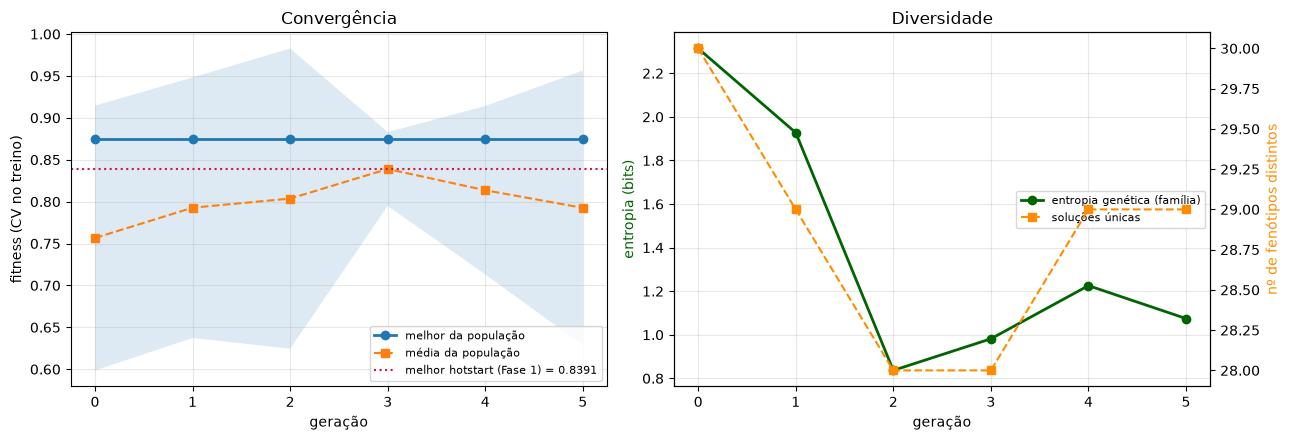

In [14]:
import matplotlib.pyplot as plt
from src.monitoramento.registro import carregar_historico

historico = carregar_historico(EXECUCAO)
fitness_hotstart = hotstart["fitness (CV)"].max()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(historico.geracao, historico.melhor_fitness, "o-", label="melhor da população", lw=2)
ax1.plot(historico.geracao, historico.fitness_medio, "s--", label="média da população", lw=1.5)
ax1.fill_between(historico.geracao,
                 historico.fitness_medio - historico.desvio_padrao,
                 historico.fitness_medio + historico.desvio_padrao, alpha=0.15)
ax1.axhline(fitness_hotstart, ls=":", color="crimson", lw=1.5,
            label=f"melhor hotstart (Fase 1) = {fitness_hotstart:.4f}")
ax1.set_xlabel("geração"); ax1.set_ylabel("fitness (CV no treino)")
ax1.set_title("Convergência"); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

ax2.plot(historico.geracao, historico.entropia_familia, "o-", color="darkgreen", lw=2,
         label="entropia genética (família)")
ax2b = ax2.twinx()
ax2b.plot(historico.geracao, historico.n_solucoes_unicas, "s--", color="darkorange", lw=1.5,
          label="soluções únicas")
ax2.set_xlabel("geração"); ax2.set_ylabel("entropia (bits)", color="darkgreen")
ax2b.set_ylabel("nº de fenótipos distintos", color="darkorange")
ax2.set_title("Diversidade"); ax2.grid(alpha=0.3)
linhas = ax2.get_lines() + ax2b.get_lines()
ax2.legend(linhas, [l.get_label() for l in linhas], fontsize=8, loc="center right")

fig.tight_layout(); plt.show()


**Leitura dos gráficos.**

**Esquerda — convergência.** O melhor fitness nunca piora (efeito do elitismo) e a média da
população sobe junto, o que indica que a pressão seletiva está funcionando: não é só a elite
que melhora, a população toda migra. A linha tracejada vermelha é o melhor hotstart — o ganho
do AG é a distância acima dela.

**Note o quanto o ganho é modesto.** Isso é consequência direta do hotstart ser bom: partindo
de uma configuração já conscientemente escolhida pela Fase 1, sobra pouca margem. Se eu tivesse
partido de defaults ruins, a curva pareceria muito mais impressionante — e diria muito menos.

**Direita — diversidade.** A entropia genética cai ao longo das gerações: a população converge
para um subconjunto de famílias. O número de fenótipos únicos é a diversidade *efetiva* — e
vale notar que essa métrica só mede o que importa porque conta **fenótipos**, não genótipos.
Contar genótipos (incluindo genes latentes) inflava a diversidade artificialmente e escondia
exatamente o sinal de convergência que o gráfico existe para mostrar.


<a id="etapa8"></a>
## 8. O que foi feito

### Feito neste notebook

| Item | Onde |
|---|---|
| Baseline da Fase 1 reproduzido e congelado | §2 |
| Codificação híbrida com gene de família e genes latentes | §3 |
| Validade por construção, verificada em 300 indivíduos | §3.3 |
| Fitness composto com peso em recall, justificado por evidência | §4.1 |
| Garantia anti-vazamento, estrutural e testada | §4.2 |
| Hotstart com os hiperparâmetros reais da Fase 1 | §5 |
| Operadores por tipo de gene; torneio justificado | §6 |
| Uma execução completa do AG, com convergência e diversidade | §7 |

### Limitações honestas desta etapa

1. **O ganho possível é estruturalmente pequeno.** O hotstart parte de uma configuração já boa,
   o dataset tem 541 registros e o espaço de busca é de dimensão modesta (3 a 7 genes por
   família). Nenhum ajuste de hiperparâmetro contorna essas três coisas.
2. **Ajustar hiperparâmetros não corrige viés de amostra.** A base vem de uma única clínica de
   fertilidade. Um modelo melhor ajustado sobre dados enviesados é um modelo que **erra com
   mais confiança** — e o Notebook 03 trata disso na seção de ética.
3. **Uma única execução não é evidência.** AG é estocástico. É por isso que o Notebook 02
   reporta média ± desvio sobre 3 sementes, e não um número isolado.
